<a href="https://colab.research.google.com/github/HesaraDi531/Practical/blob/main/Labsheet1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cpu


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Training stories: 900
Validation stories: 100
Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big hill. They think maybe there is a beautiful flower on top of the hill. They run to the hill. They jump over rocks and sticks. They climb up the hill. They are tired, but they are happy.

They reach th
Vocabulary size: 75
Encoded sample: [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]
Decoded sample: Once upon a time
Number of parameters: 80715
Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])
Epoch 01 | Train loss: 2.888 | Validation loss: 2.526
Epoch 02 | Train loss: 2.416 | Validation loss: 2.354
Epoch 03 | Train loss: 2.306 | Validation loss: 2.252
Epoch 04 | Train loss: 2.202 | Validation loss: 2.150
Epoch 05 | Train loss: 2.090 | V

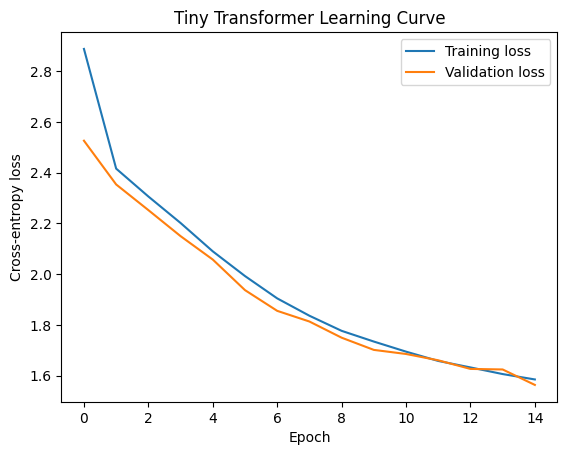

Validation loss: 1.5889
Validation perplexity: 4.90
Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f5d4599d2d41d5da6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip -q install datasets

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

"""Step 2-Load the TinyStories dataset (A dataset publicly available in Hugging face)"""

dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print(train_text[:500])

"""Step 3-Convert text into numerical IDs

This experiment uses character-level tokenization: each unique character receives an integer ID.
"""

chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Encoded sample:", encode("Once upon a time")[:10])
print("Decoded sample:", decode(encode("Once upon a time")))

"""Step 4 — Define the tiny Transformer"""

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, 64)
        self.pos_emb = nn.Embedding(64, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=2,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        positions = torch.arange(T, device=idx.device)

        x = self.token_emb(idx) + self.pos_emb(positions)

        # Prevent each position from seeing future characters
        mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.blocks(x, mask=mask)

        return self.lm_head(x)

    @torch.no_grad()
    def generate_tokens(self, idx, max_new_tokens):
        # Generates new tokens autoregressively
        for _ in range(max_new_tokens):
            # Crop context if it exceeds the maximum block size (64)
            idx_cond = idx[:, -64:]
            logits = self(idx_cond)
            # Focus only on the last step
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


model = TinyTransformer().to(device)

print(
    "Number of parameters:",
    sum(p.numel() for p in model.parameters())
)

"""Step 5 — Prepare input and target sequences"""

block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)


x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

"""Step 6 — Train the Transformer"""

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x, y = get_batch(split_name)
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)


for epoch in range(15):
    model.train()
    total_loss = 0.0

    for step in range(100):
        x, y = get_batch("train")

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}"
    )

"""Step 7 — Plot the training and validation losses"""

import matplotlib.pyplot as plt

plt.plot(train_history, label="Training loss")
plt.plot(val_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()
plt.show()

"""Step 8 — Calculate validation perplexity


"""

val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}")

"""Step 11 — Save the trained model"""

checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": 64,
        "feedforward_dim": 128
    }
}

torch.save(checkpoint, "tiny_transformer.pt")

print("Model saved successfully!")

from google.colab import files

files.download("tiny_transformer.pt")

"""Step 10 -Built basic chat with the model trained"""

!pip -q install gradio

import gradio as gr

def generate(prompt, max_new_chars=100):
    model.eval()
    # Convert input string to tokens
    encoded = encode(prompt)
    idx = torch.tensor([encoded], dtype=torch.long, device=device)
    # Generate new tokens
    generated_idx = model.generate_tokens(idx, max_new_chars)
    # Decode and return text
    return decode(generated_idx[0].tolist())

def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."

    if "stoi" not in globals() or "generate" not in globals():
        return "Error: Please run the cells that define stoi and generate first."

    supported = "".join(ch for ch in message if ch in stoi)

    if not supported:
        return "Please try text using characters in the training dataset."

    try:
        return generate(supported, max_new_chars=100)
    except Exception as e:
        return f"Text generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A language model trained from scratch in our LLM class."
)

demo.launch()